<img src = "https://drive.google.com/uc?export=view&id=1A9dhO0gYByNJf9ya0SZmeCzZIeepRhsO" alt = "Encabezado MLDS" width = "100%">  </img>

# **Modelamiento y Validación**
---

Este notebook es una plantilla que le puede servir como guía para el cuarto entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. **Hernando Jose Vela — 17593509**
2. **Oscar Javier Restrepo — 79660922**
3. **Juan David Vasquez Pinzon — 1002459526**

## **1. Selección y diseño de modelos**
---

Seleccione el/los modelo/s a explorar para aplicar sobre el conjunto de datos. Recuerde que la selección del modelo está influenciada por diferentes factores.

Además, debe definir cuál es su problema:

- **Regresión**: se busca estimar un valor continúo a partir de los datos.
- **Clasificación**: permite estimar un valor categórico a partir de los datos.
- **Agrupamiento**: permite encontrar grupos de datos similares.
- **Otros modelos**: recuerde que dispone de otros tipos de tareas supervisadas y no supervisadas.

Justifique la selección y el diseño de los modelos a explorar.

---**INGRESE SU RESPUESTA**---

### **1.1. Definición del problema y continuidad del proyecto**

El proyecto corresponde a un problema de **clasificación supervisada binaria**, cuyo objetivo es identificar la presencia o ausencia de enfermedad cardíaca a partir de características clínicas y demográficas.

Se utilizará la variable objetivo `HeartDisease`:

- **Clase 0:** ausencia de enfermedad cardíaca.
- **Clase 1:** presencia de enfermedad cardíaca.

Esta formulación mantiene el objetivo establecido en la fase de entendimiento del negocio. El resultado será un prototipo académico de clasificación; no se pretende predecir ataques cardíacos futuros, estimar mortalidad ni sustituir el diagnóstico médico.

La selección de modelos considera los resultados de las entregas anteriores:

- Se dispone de **918 registros**.
- La variable objetivo presenta **508 registros positivos y 410 negativos**, lo que representa un desbalance moderado en términos de proporciones, sin justificar por sí solo un sobremuestreo.
- Se conservaron las observaciones y los valores extremos que no pudieron identificarse como errores.
- Los ceros de `Cholesterol` y `RestingBP` se trataron como valores no utilizables, representándolos mediante valores ausentes.
- Se definió una partición estratificada de **734 registros de entrenamiento y 184 de prueba**, con `random_state=42`.


### **1.2. Variables de entrada y salida**

**Variables de entrada**

Se utilizarán las 11 características originales seleccionadas en la fase de preparación:

| Tipo | Variables |
|---|---|
| Numéricas | `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak` |
| Categóricas | `Sex`, `ChestPainType`, `FastingBS`, `RestingECG`, `ExerciseAngina`, `ST_Slope` |

La configuración inicial también incluirá **`Cholesterol_missing`**, que identifica registros cuyo colesterol se consideró ausente durante la preparación.

Se comparará esta configuración con otra que excluya dicho indicador. Su asociación con la etiqueta podría reflejar diferencias de registro o procedencia, por lo que no debe interpretarse automáticamente como información clínica generalizable.

**Variable de salida**

La salida será una predicción de `HeartDisease`. Esta variable se excluirá de las características y no se utilizará para imputar valores faltantes.

Los índices de las filas se conservarán únicamente para trazabilidad y tampoco se incorporarán como variables predictoras.

### **1.3. Modelos seleccionados y justificación**

Se explorarán tres clasificadores con diferentes mecanismos de aprendizaje y un modelo de referencia.

| Modelo | Justificación | Aspectos que se controlarán |
|---|---|---|
| **Clasificador de referencia — DummyClassifier** | Predice siempre la clase mayoritaria. Permite comprobar si los modelos aportan una mejora frente a una estrategia sencilla. | Se evaluará con las mismas particiones y métricas. |
| **Regresión logística — LogisticRegression** | Es apropiada para clasificación binaria, tiene un costo computacional reducido y permite examinar asociaciones mediante sus coeficientes. Proporciona una referencia interpretable con regularización. | Intensidad de regularización, ponderación de clases y convergencia. Los coeficientes no se interpretarán como efectos causales. |
| **Vecinos más cercanos — KNeighborsClassifier** | Permite explorar si pacientes con características similares presentan etiquetas similares. Representa una alternativa no lineal y mantiene continuidad con los modelos propuestos en la fase 1. | Número de vecinos, ponderación por distancia y sensibilidad a escalas y valores extremos. |
| **Bosque aleatorio — RandomForestClassifier** | Permite representar relaciones no lineales e interacciones entre variables sin definirlas manualmente. Complementa los enfoques anteriores mediante un conjunto de árboles. | Profundidad de los árboles y tamaño mínimo de las hojas para limitar el sobreajuste. |

La comparación permite contrastar un modelo lineal, uno basado en distancias y otro basado en árboles. No se asumirá de antemano que el modelo más complejo tendrá mejor desempeño.

No se utilizará agrupamiento como solución principal porque se dispone de etiquetas y el objetivo es predecirlas. Tampoco se aplicará PCA inicialmente: la representación obtenida en la fase anterior tiene una dimensionalidad manejable y se desea conservar la interpretación de las características.

### **1.4. Diseño del preprocesamiento y los modelos**

Cada clasificador se integrará en un **Pipeline** junto con el preprocesamiento correspondiente.

El procedimiento incluirá:

1. **Imputación numérica mediante la mediana**, calculada exclusivamente con los datos disponibles para entrenamiento.
2. **Codificación One-Hot** de las variables categóricas.
3. **Estandarización de las variables numéricas** para regresión logística y KNN.
4. **Conservación del indicador binario sin escalado**, cuando se evalúe la configuración que lo incluye.
5. **Entrenamiento del clasificador** con las características transformadas.

Para Random Forest se conservarán la imputación y la codificación, pero se omitirá el escalado numérico porque sus divisiones no requieren una escala común.

Durante la validación cruzada, cada Pipeline aprenderá sus medianas, categorías y parámetros de escala exclusivamente con el subconjunto de entrenamiento de cada pliegue.

**No se utilizarán directamente las matrices previamente escaladas de la fase 3 como entrada de GridSearchCV.** Se utilizarán las características anteriores al ajuste estadístico y se incorporará el preprocesador dentro del Pipeline, evitando compartir información entre los pliegues.


### **1.5. Diseño de la experimentación**

Se conservará la partición de entrenamiento y prueba de la fase anterior. Si se reconstruye, se mantendrán el mismo archivo, orden de registros, estratificación y semilla.

Sobre los **734 registros de entrenamiento** se realizará una validación cruzada estratificada de **cinco pliegues**, con mezcla reproducible y `random_state=42`.

Se utilizarán los mismos pliegues para comparar modelos. La búsqueda inicial de hiperparámetros será acotada:

| Modelo | Hiperparámetros propuestos |
|---|---|
| Regresión logística | `C`: 0.01, 0.1, 1 y 10; `class_weight`: None y `"balanced"`. |
| KNN | `n_neighbors`: 3, 5, 9 y 15; `weights`: `"uniform"` y `"distance"`. |
| Random Forest | `n_estimators`: 200; `max_depth`: 5, 10 y None; `min_samples_leaf`: 1 y 5. |

Estas combinaciones se evaluarán con y sin `Cholesterol_missing`. Se registrarán los hiperparámetros, la media y desviación estándar de las métricas entre pliegues y el tiempo de ajuste.

La ponderación de clases se tratará como una alternativa experimental, no como una corrección obligatoria. No se aplicará sobremuestreo inicialmente.


### **1.6. Criterios de evaluación y selección**

Se utilizará como criterio principal el **F1 de la clase positiva (`HeartDisease = 1`)**, porque combina precisión y recall y permite evitar una selección basada exclusivamente en la exactitud.

Se reportarán también:

- **Recall de la clase positiva:** proporción de casos con enfermedad identificados.
- **Precisión de la clase positiva:** proporción de predicciones positivas que son correctas.
- **Exactitud:** proporción total de clasificaciones correctas.
- **ROC-AUC:** capacidad de discriminar entre las clases a partir de probabilidades o puntuaciones.
- **Matriz de confusión:** cantidades de verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos.

Se prestará especial atención a los falsos negativos, en coherencia con el objetivo del proyecto. Sin embargo, no se maximizará el recall de manera aislada, pues predecir todos los registros como positivos produciría un recall alto sin una clasificación útil.

La configuración final se seleccionará por el mayor F1 medio en validación cruzada. En caso de empate, se priorizará el mayor recall y, si persiste, la alternativa más sencilla. La variabilidad entre pliegues se reportará para contextualizar las diferencias; su desviación estándar no se interpretará como un intervalo de confianza.


### **1.7. Evaluación final y alcance**

Una vez seleccionados el modelo, sus hiperparámetros y la configuración de características, se reajustará el Pipeline con todos los datos de entrenamiento y se evaluará en los **184 registros de prueba**.

El conjunto de prueba no se utilizará para elegir modelos, ajustar hiperparámetros, seleccionar el indicador de faltantes ni modificar umbrales de decisión.

Se reconocerá que el conjunto completo ya fue explorado en fases anteriores. El protocolo evita fuga durante el ajuste, pero no elimina ese conocimiento previo ni sustituye una validación externa.

Esta sección define el diseño experimental. Los resultados, la comparación de modelos y las conclusiones de desempeño se incorporarán después de ejecutar los experimentos.

## **2. Entrenamiento del Modelo y Selección de Hiperparámetros**
---

Entrene el modelo y consiga la combinación eficiente de hiperparámetros para obtener un rendimiento óptimo.

Es importante visualizar los resultados de manera clara y comprensible. Para esto, **se deben utilizar tablas y gráficos** que muestren cómo cambian las métricas de desempeño del proceso de entrenamiento en función de los hiperparámetros probados. Algunas herramientas visuales útiles incluyen las *curvas de aprendizaje* y las *curvas de validación,* que nos permiten comparar el rendimiento del modelo con diferentes ajustes de hiperparámetros.

Continuación de las fases 1–3: clasificación binaria de HeartDisease. Se conservan la limpieza determinista y la partición estratificada 80/20 con semilla 42. Cargue heart.csv junto al notebook o permita la descarga pública de Kaggle.

Diseño: tres familias (LogisticRegression, KNN y RandomForest), con/sin indicador de colesterol, 44 configuraciones y cinco pliegues compartidos: 220 ajustes de búsqueda. Se añaden 5 ajustes de referencia, 25 de curva de aprendizaje y 1 reajuste final. PCA no es necesario para estas 22 características transformadas.

Criterio: mayor F1 positivo medio; en empate, recall y prioridad de familia sencilla (logística, KNN, bosque), sin indicador y orden del grid. Una mejora pequeña en CV no prueba superioridad estadística. Las desviaciones entre pliegues no son intervalos de confianza. La búsqueda es acotada: no demuestra un óptimo global.

Prevención de fuga: todos los parámetros de imputación, codificación y escala se estiman dentro de cada pliegue mediante Pipeline. La prueba no participa en la selección. La exploración global de fases previas sigue siendo una limitación; se requeriría validación externa para uso clínico.

Métricas: F1, recall y precisión de clase 1; accuracy y ROC-AUC complementarias. Se mantienen umbrales/reglas de decisión predeterminados, sin optimizarlos con prueba.

Ejecutar todas las celdas en orden. El proceso puede tardar varios minutos; las versiones y el hash se registran al final.

In [ ]:
# SECCIÓN 2. Entrenamiento y selección de hiperparámetros
# Ejecutar en Colab/Jupyter. El test se separa, pero NO se evalúa aquí.
from pathlib import Path
import io
import zipfile
import hashlib
import json
import platform
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_validate, learning_curve,
)
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

### **2.1. Estrategia de entrenamiento**

Se entrenaron y compararon tres modelos de clasificación supervisada: **regresión logística, vecinos más cercanos (KNN) y Random Forest**. Adicionalmente, se utilizó un clasificador de referencia que predice siempre la clase mayoritaria.

Se mantuvo la partición estratificada definida en la fase de preparación:

- **Entrenamiento:** 734 registros, correspondientes aproximadamente al 80 % del conjunto.
- **Prueba:** 184 registros, correspondientes aproximadamente al 20 %.
- **Semilla aleatoria:** `random_state=42`.

La búsqueda de hiperparámetros se realizó exclusivamente sobre el conjunto de entrenamiento mediante **validación cruzada estratificada de cinco pliegues**. Se utilizaron los mismos pliegues para comparar todas las configuraciones.

El conjunto de prueba permaneció reservado para la evaluación final y no intervino en la selección del modelo.


In [ ]:
# 2.1. Reconstruir exactamente la partición de la fase 3.
SEED = 42
OUT = Path('salidas_fase4')
OUT.mkdir(exist_ok=True)
path = Path('heart.csv')
if path.exists():
    contenido_csv = path.read_bytes()
else:
    url = 'https://www.kaggle.com/api/v1/datasets/download/fedesoriano/heart-failure-prediction'
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        if archive.testzip() is not None:
            raise ValueError('Archivo ZIP dañado.')
        contenido_csv = archive.read('heart.csv')
    path.write_bytes(contenido_csv)

df_original = pd.read_csv(io.BytesIO(contenido_csv))
df = df_original.copy(deep=True)
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
indicator_cols = ['Cholesterol_missing']
assert df.shape == (918, 12), 'Verifique que utiliza el mismo CSV de la fase 3.'
assert df['HeartDisease'].isin([0, 1]).all()
# Reglas fijas: no estiman estadísticas ni utilizan la etiqueta.
df['Cholesterol_missing'] = (df['Cholesterol'].eq(0) | df['Cholesterol'].isna()).astype(int)
df[['Cholesterol', 'RestingBP']] = df[['Cholesterol', 'RestingBP']].replace(0, np.nan)
X = df[num_cols + cat_cols + indicator_cols].copy()
y = df['HeartDisease'].copy()
assert not X.duplicated().any(), 'Revisar partición por grupos ante predictoras repetidas.'
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
assert X_train.index.intersection(X_test.index).empty
print(f'Entrenamiento: {len(X_train)}; prueba reservada: {len(X_test)}.')

Entrenamiento: 734; prueba reservada: 184.


### **2.2. Preprocesamiento dentro de la validación cruzada**

Cada modelo se integró en un `Pipeline` con las transformaciones necesarias:

1. Imputación de valores numéricos ausentes mediante la mediana.
2. Imputación de valores categóricos ausentes mediante la categoría más frecuente.
3. Codificación de las variables categóricas mediante `OneHotEncoder`.
4. Estandarización de las variables numéricas para regresión logística y KNN.
5. Entrenamiento del clasificador.

En Random Forest se omitió el escalado numérico porque sus divisiones no requieren una escala común.

Las transformaciones se ajustaron únicamente con los datos de entrenamiento de cada pliegue. Esto evita que la información de validación participe en el cálculo de medianas, categorías o parámetros de escalado.

También se compararon dos alternativas:

- **Con `Cholesterol_missing`:** incorpora el indicador de colesterol originalmente ausente o registrado como cero.
- **Sin `Cholesterol_missing`:** utiliza únicamente las características originales.

Esta comparación permite estudiar la utilidad del indicador, reconociendo que podría representar diferencias de procedencia o de registro y no exclusivamente información clínica.

In [ ]:
# 2.2. Preprocesador nuevo dentro de cada Pipeline y pliegue.
def crear_preprocesador(escalar=True):
    numeric_steps = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        numeric_steps.append(('escalar', StandardScaler()))
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return ColumnTransformer([
        ('num', Pipeline(numeric_steps), num_cols),
        ('cat', Pipeline([
            ('imputar', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder),
        ]), cat_cols),
        # GridSearch comparará paso directo frente a excluir el indicador.
        ('indicador', 'passthrough', indicator_cols),
    ], remainder='drop', sparse_threshold=0)

scoring = {
    'f1': make_scorer(f1_score, pos_label=1, zero_division=0),
    'recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'accuracy': 'accuracy',
    'roc_auc': 'roc_auc',
}
# Materializar los índices garantiza exactamente los mismos pliegues.
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train, y_train))

### **2.3. Hiperparámetros explorados**

Se utilizó `GridSearchCV` para evaluar sistemáticamente las siguientes combinaciones:

| Modelo | Hiperparámetro | Valores explorados |
|---|---|---|
| Regresión logística | `C` | 0.01, 0.1, 1 y 10 |
| Regresión logística | `class_weight` | None y `"balanced"` |
| KNN | `n_neighbors` | 3, 5, 9 y 15 |
| KNN | `weights` | `"uniform"` y `"distance"` |
| Random Forest | `n_estimators` | 200, fijado para todas sus configuraciones |
| Random Forest | `max_depth` | 5, 10 y None |
| Random Forest | `min_samples_leaf` | 1 y 5 |
| Todos los modelos | Indicador de colesterol | Incluido y excluido |

Se evaluaron **44 configuraciones**, distribuidas así:

- Regresión logística: 16 configuraciones.
- KNN: 16 configuraciones.
- Random Forest: 12 configuraciones.

Con cinco pliegues por configuración, la búsqueda requirió **220 ajustes**. A estos se añadieron los ajustes del clasificador de referencia, la curva de aprendizaje y el reajuste final del modelo seleccionado.

La búsqueda es acotada a los valores indicados; por tanto, identifica la mejor configuración del experimento, no un óptimo global.


In [ ]:
# 2.3. Referencia: no aprende patrones de las características.
baseline_cv = cross_validate(
    DummyClassifier(strategy='most_frequent'), X_train, y_train,
    cv=cv, scoring=scoring, error_score='raise', n_jobs=1,
)
baseline = pd.DataFrame([
    {'Metrica': metric, 'Media CV': baseline_cv['test_' + metric].mean(),
     'Desviacion CV': baseline_cv['test_' + metric].std(ddof=0)}
    for metric in scoring
])
print('\nReferencia: clase mayoritaria')
display(baseline.round(4))


Referencia: clase mayoritaria


,Metrica,Media CV,Desviacion CV
0,f1,0.7123,0.0023
1,recall,1.0000,0.0000
2,precision,0.5531,0.0028
3,accuracy,0.5531,0.0028
4,roc_auc,0.5000,0.0000


### **2.4. Criterio de selección**

Se utilizó como criterio principal el **F1 de la clase positiva**, correspondiente a `HeartDisease = 1`.

Esta métrica combina precisión y recall, permitiendo evaluar conjuntamente la detección de casos positivos y la proporción de falsas alarmas.

También se registraron:

- Recall de la clase positiva.
- Precisión de la clase positiva.
- Exactitud.
- ROC-AUC.
- Desviación estándar de las métricas entre pliegues.
- Tiempo medio de ajuste.
- Diferencia entre el F1 de entrenamiento y el de validación.

La selección se realizó por el mayor F1 medio de validación. En caso de empate, se priorizó el recall y posteriormente la alternativa más sencilla según el orden definido para las familias de modelos.

La desviación estándar entre pliegues se utiliza como descripción de variabilidad y no como un intervalo de confianza.


In [ ]:
# 2.4. Espacios acotados: 16 + 16 + 12 = 44 configuraciones, 220 ajustes CV.
# Se fija n_jobs=1 para evitar saturar memoria y procesos en Colab/Windows.
experimentos = {
    'Logistica': (LogisticRegression(max_iter=5000, solver='lbfgs', random_state=SEED), True, {
        'modelo__C': [0.01, 0.1, 1, 10],
        'modelo__class_weight': [None, 'balanced'],
    }),
    'KNN': (KNeighborsClassifier(), True, {
        'modelo__n_neighbors': [3, 5, 9, 15],
        'modelo__weights': ['uniform', 'distance'],
    }),
    'RandomForest': (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), False, {
        'modelo__max_depth': [5, 10, None],
        'modelo__min_samples_leaf': [1, 5],
    }),
}
busquedas, tablas = {}, []
for nombre, (estimador, escalar, parametros) in experimentos.items():
    print(f'Entrenando {nombre}...', flush=True)
    pipeline = Pipeline([
        ('preparacion', crear_preprocesador(escalar)),
        ('modelo', estimador),
    ])
    grid = {**parametros, 'preparacion__indicador': ['drop', 'passthrough']}
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=scoring, refit=False,
        return_train_score=True, n_jobs=1, error_score='raise',
    )
    search.fit(X_train, y_train)
    busquedas[nombre] = search
    table = pd.DataFrame(search.cv_results_)
    table['Modelo'] = nombre
    table['Configuracion'] = np.arange(len(table))
    table['Indicador'] = table['param_preparacion__indicador'].map({'drop': 'Sin indicador', 'passthrough': 'Con indicador'})
    table['Brecha_F1'] = table['mean_train_f1'] - table['mean_test_f1']
    tablas.append(table)

resultados = pd.concat(tablas, ignore_index=True)
assert len(resultados) == 44
assert np.isfinite(resultados['mean_test_f1']).all()
# Desempate explícito: F1, recall, familia más sencilla, sin indicador y orden del grid.
resultados['Prioridad'] = resultados['Modelo'].map({'Logistica': 0, 'KNN': 1, 'RandomForest': 2})
resultados['Complejidad_indicador'] = resultados['Indicador'].eq('Con indicador').astype(int)
ranking = resultados.sort_values(
    ['mean_test_f1', 'mean_test_recall', 'Prioridad', 'Complejidad_indicador', 'Configuracion'],
    ascending=[False, False, True, True, True], kind='stable',
)
mejores = ranking.drop_duplicates('Modelo')
columnas = ['Modelo', 'Indicador', 'mean_train_f1', 'mean_test_f1', 'std_test_f1',
            'mean_test_recall', 'mean_test_precision', 'mean_test_accuracy',
            'mean_test_roc_auc', 'Brecha_F1', 'mean_fit_time', 'params']
print('\nMejor configuración de cada familia (test en cv_results_ significa validación del pliegue):')
display(mejores[columnas].round(4))
print('\nTodas las configuraciones:')
display(ranking[columnas].round(4))

Entrenando Logistica...
Entrenando KNN...
Entrenando RandomForest...

Mejor configuración de cada familia (test en cv_results_ significa validación del pliegue):


,Modelo,Indicador,mean_train_f1,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_accuracy,mean_test_roc_auc,Brecha_F1,mean_fit_time,params
35,RandomForest,Con indicador,0.9051,0.8863,0.0295,0.9163,0.8589,0.8692,0.9332,0.0188,0.2753,"{'modelo__max_depth': 5, 'modelo__min_samples_..."
5,Logistica,Con indicador,0.8815,0.8751,0.0258,0.8917,0.8604,0.8583,0.9256,0.0064,0.0210,"{'modelo__C': 0.1, 'modelo__class_weight': Non..."
29,KNN,Con indicador,0.8766,0.8720,0.0268,0.8793,0.8650,0.8570,0.9162,0.0047,0.0130,"{'modelo__n_neighbors': 15, 'modelo__weights':..."



Todas las configuraciones:


,Modelo,Indicador,mean_train_f1,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_accuracy,mean_test_roc_auc,Brecha_F1,mean_fit_time,params
35,RandomForest,Con indicador,0.9051,0.8863,0.0295,0.9163,0.8589,0.8692,0.9332,0.0188,0.2753,"{'modelo__max_depth': 5, 'modelo__min_samples_..."
41,RandomForest,Con indicador,1.0000,0.8788,0.0225,0.8991,0.8623,0.8624,0.9284,0.1212,0.2970,"{'modelo__max_depth': None, 'modelo__min_sampl..."
39,RandomForest,Con indicador,0.9180,0.8783,0.0297,0.9015,0.8576,0.8610,0.9336,0.0396,0.2753,"{'modelo__max_depth': 10, 'modelo__min_samples..."
43,RandomForest,Con indicador,0.9177,0.8759,0.0288,0.8991,0.8551,0.8583,0.9336,0.0418,0.3801,"{'modelo__max_depth': None, 'modelo__min_sampl..."
36,RandomForest,Sin indicador,0.9936,0.8752,0.0202,0.8966,0.8577,0.8583,0.9294,0.1184,0.2941,"{'modelo__max_depth': 10, 'modelo__min_samples..."
5,Logistica,Con indicador,0.8815,0.8751,0.0258,0.8917,0.8604,0.8583,0.9256,0.0064,0.0210,"{'modelo__C': 0.1, 'modelo__class_weight': Non..."
42,RandomForest,Sin indicador,0.9162,0.8747,0.0304,0.8991,0.8536,0.8570,0.9322,0.0415,0.2906,"{'modelo__max_depth': None, 'modelo__min_sampl..."
37,RandomForest,Con indicador,0.9927,0.8745,0.0237,0.8892,0.8634,0.8583,0.9305,0.1182,0.2924,"{'modelo__max_depth': 10, 'modelo__min_samples..."
33,RandomForest,Con indicador,0.9157,0.8743,0.0256,0.8966,0.8553,0.8570,0.9324,0.0414,0.2959,"{'modelo__max_depth': 5, 'modelo__min_samples_..."
38,RandomForest,Sin indicador,0.9182,0.8734,0.0325,0.8967,0.8531,0.8556,0.9321,0.0449,0.3618,"{'modelo__max_depth': 10, 'modelo__min_samples..."


### **2.5. Resultados del clasificador de referencia**

El clasificador de referencia predijo siempre la clase positiva, que es la mayoritaria en entrenamiento.

| Métrica | Media en validación cruzada |
|---|---:|
| Exactitud | 0.5531 |
| Precisión | 0.5531 |
| Recall | 1.0000 |
| F1 | 0.7123 |
| ROC-AUC | 0.5000 |

Aunque alcanza un recall de 1, este resultado se debe a que clasifica todos los registros como positivos. Su ROC-AUC de 0.5 muestra que no discrimina entre las clases.

Este comportamiento justifica no seleccionar modelos utilizando únicamente el recall.


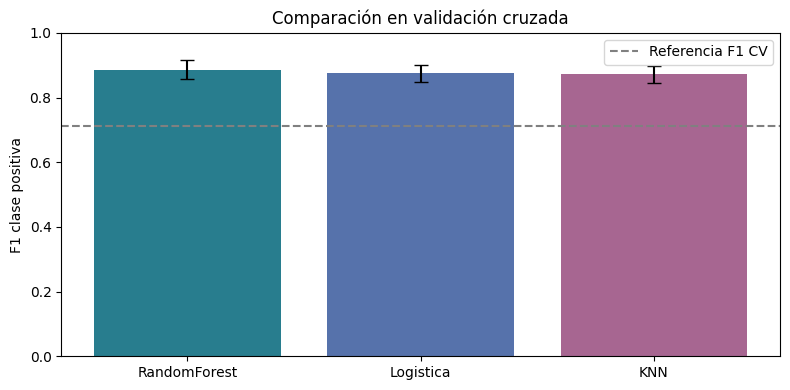

In [ ]:
# 2.5. Comparación de familias; barras de error = desviación entre pliegues.
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(mejores['Modelo'], mejores['mean_test_f1'], yerr=mejores['std_test_f1'],
       capsize=5, color=['#287D8E', '#5672AB', '#A76691'])
ax.axhline(baseline_cv['test_f1'].mean(), color='gray', linestyle='--', label='Referencia F1 CV')
ax.set(ylabel='F1 clase positiva', ylim=(0, 1), title='Comparación en validación cruzada')
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'comparacion_modelos.png', dpi=150)
plt.show()

### **2.6. Comparación de los modelos**

Las mejores configuraciones de cada familia obtuvieron los siguientes resultados:

| Modelo | F1 medio de validación | Desviación estándar del F1 | Recall medio de validación |
|---|---:|---:|---:|
| **Random Forest** | **0.8863** | **0.0295** | **0.9163** |
| Regresión logística | 0.8751 | 0.0258 | 0.8917 |
| KNN | 0.8720 | 0.0268 | 0.8793 |

Las tres familias superaron el F1 del clasificador de referencia.

Random Forest obtuvo el mayor F1 medio dentro de la búsqueda realizada. Sin embargo, las diferencias observadas no demuestran por sí solas superioridad estadística ni garantizan el mismo orden de desempeño en datos externos.

Las mejores configuraciones fueron:

| Modelo | Configuración seleccionada |
|---|---|
| Regresión logística | `C=0.1`, `class_weight=None`, con indicador de colesterol |
| KNN | `n_neighbors=15`, `weights="uniform"`, con indicador de colesterol |
| Random Forest | `n_estimators=200`, `max_depth=5`, `min_samples_leaf=5`, con indicador de colesterol |


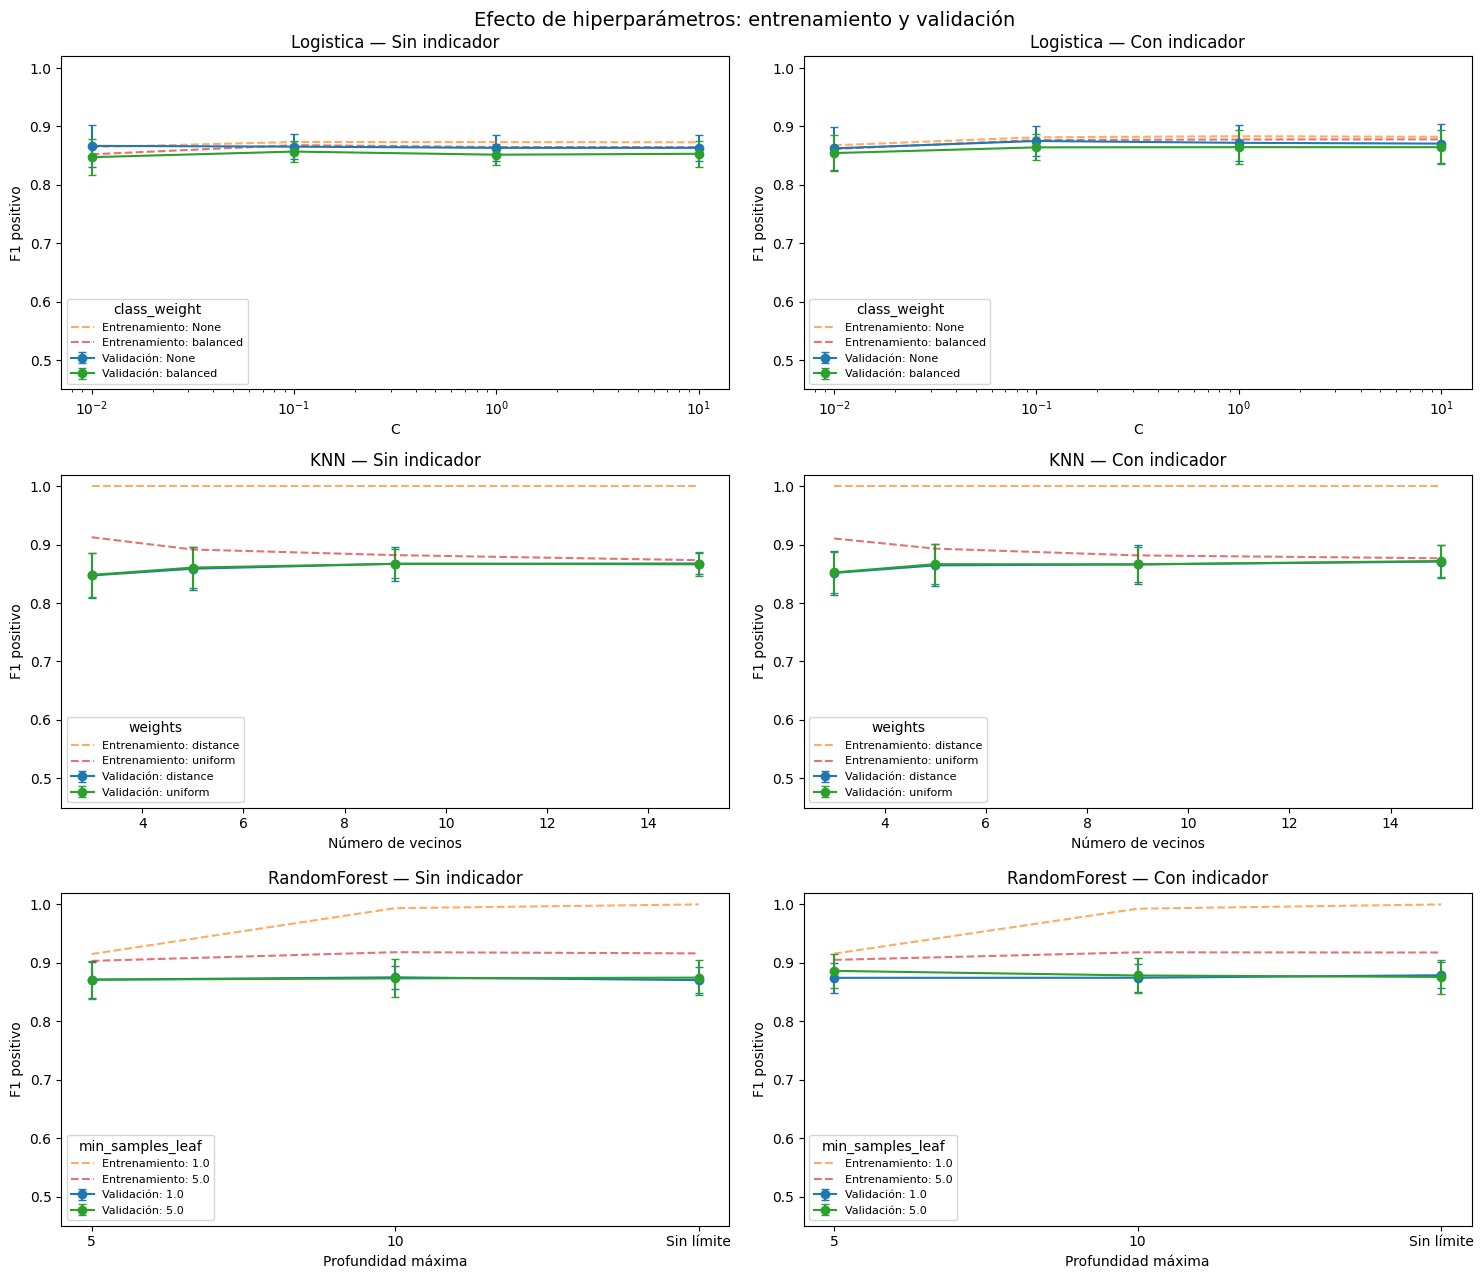

In [ ]:
# 2.6. Curvas de validación derivadas de TODOS los resultados del grid.
# Cada línea mantiene fijos el parámetro secundario y el uso del indicador.
settings = [
    ('Logistica', 'param_modelo__C', 'param_modelo__class_weight', 'C'),
    ('KNN', 'param_modelo__n_neighbors', 'param_modelo__weights', 'Número de vecinos'),
    ('RandomForest', 'param_modelo__max_depth', 'param_modelo__min_samples_leaf', 'Profundidad máxima'),
]
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for row, (nombre, parametro, secundario, label) in enumerate(settings):
    for col, indicador in enumerate(['Sin indicador', 'Con indicador']):
        ax = axes[row, col]
        subset = resultados[(resultados['Modelo'] == nombre) & (resultados['Indicador'] == indicador)].copy()
        subset['Ajuste secundario'] = subset[secundario].map(lambda v: 'None' if pd.isna(v) else str(v))
        for setting, group in subset.groupby('Ajuste secundario'):
            if nombre == 'RandomForest':
                group['orden'] = group[parametro].map(lambda v: 99 if pd.isna(v) else int(v))
                group = group.sort_values('orden')
                x = np.arange(len(group))
                ax.set_xticks(x, ['Sin límite' if pd.isna(v) else str(int(v)) for v in group[parametro]])
            else:
                group = group.sort_values(parametro)
                x = group[parametro].astype(float).to_numpy()
            ax.errorbar(x, group['mean_test_f1'], yerr=group['std_test_f1'], marker='o', capsize=3, label=f'Validación: {setting}')
            ax.plot(x, group['mean_train_f1'], '--', alpha=0.65, label=f'Entrenamiento: {setting}')
        if nombre == 'Logistica':
            ax.set_xscale('log')
        ax.set(title=f'{nombre} — {indicador}', xlabel=label, ylabel='F1 positivo', ylim=(0.45, 1.02))
        ax.legend(fontsize=8, title=secundario.replace('param_modelo__', ''))
fig.suptitle('Efecto de hiperparámetros: entrenamiento y validación', fontsize=14)
fig.tight_layout()
fig.savefig(OUT / 'curvas_validacion.png', dpi=150)
plt.show()

### **2.7. Interpretación de las curvas de validación**

Los gráficos muestran cómo cambia el F1 de entrenamiento y validación al modificar los hiperparámetros, manteniendo identificadas las configuraciones secundarias y la inclusión del indicador.

**Regresión logística**

La configuración con `C=0.1` y sin ponderación adicional de clases obtuvo el mejor resultado de esta familia. Incrementar `C` no produjo una mejora sostenida, lo que indica que reducir la regularización no garantiza mejor generalización.

**KNN**

La mejor configuración utilizó 15 vecinos y ponderación uniforme.

Con ponderación por distancia, el F1 de entrenamiento alcanzó 1 porque cada observación utilizada para evaluar el entrenamiento puede encontrarse a sí misma como vecino. Este resultado no implica una clasificación perfecta de registros nuevos.

**Random Forest**

Los árboles más profundos y con hojas pequeñas elevaron el desempeño de entrenamiento, en algunas configuraciones hasta valores cercanos a 1, sin una mejora equivalente en validación.

La configuración con profundidad máxima de 5 y un mínimo de 5 observaciones por hoja obtuvo el mejor F1 medio de validación. Esto respalda el uso de restricciones de complejidad para reducir el sobreajuste en este experimento.


,Ejemplos por ajuste,F1 entrenamiento,F1 validacion,Desviacion validacion
0,117,0.8969,0.8754,0.0406
1,234,0.9058,0.8682,0.0361
2,352,0.9081,0.8780,0.0298
3,469,0.9033,0.8847,0.0293
4,587,0.9037,0.8826,0.0338


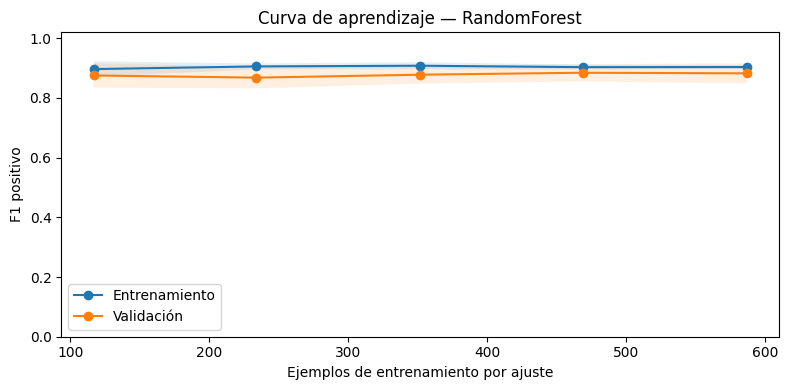

**Modelo seleccionado:** RandomForest. **F1 medio CV:** 0.8863; **recall medio CV:** 0.9163. **Hiperparámetros:** `{'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'preparacion__indicador': 'passthrough'}`. El pipeline se reajustó con los 734 registros de entrenamiento. Los 184 registros de prueba permanecen reservados para la sección 3.

Variables disponibles para continuar: modelo_final, X_test, y_test, resultados, mejores.


In [ ]:
# 2.7. Selección definitiva usando solamente validación.
ganador = ranking.iloc[0]
nombre_ganador = ganador['Modelo']
mejores_parametros = ganador['params']
modelo_final = clone(busquedas[nombre_ganador].estimator).set_params(**mejores_parametros)
modelo_final.fit(X_train, y_train)

# Curva de aprendizaje: se clona el pipeline en cada tamaño y pliegue.
# La configuración ya fue seleccionada con estos datos; la curva es diagnóstica,
# no una estimación independiente del desempeño final.
tamanos, train_scores, val_scores = learning_curve(
    clone(modelo_final), X_train, y_train, cv=cv,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], scoring=scoring['f1'],
    shuffle=True, random_state=SEED, n_jobs=1, error_score='raise',
)
curva = pd.DataFrame({
    'Ejemplos por ajuste': tamanos,
    'F1 entrenamiento': train_scores.mean(axis=1),
    'F1 validacion': val_scores.mean(axis=1),
    'Desviacion validacion': val_scores.std(axis=1),
})
display(curva.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
for scores, label in [(train_scores, 'Entrenamiento'), (val_scores, 'Validación')]:
    media, std = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tamanos, media, marker='o', label=label)
    ax.fill_between(tamanos, media - std, media + std, alpha=0.12)
ax.set(xlabel='Ejemplos de entrenamiento por ajuste', ylabel='F1 positivo',
       title=f'Curva de aprendizaje — {nombre_ganador}', ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'curva_aprendizaje.png', dpi=150)
plt.show()

# Exportar evidencia. No se llama a predict(X_test) ni score(X_test, y_test).
ranking[columnas].to_csv(OUT / 'resultados_completos.csv', index=False)
mejores[columnas].to_csv(OUT / 'mejores_por_modelo.csv', index=False)
baseline.to_csv(OUT / 'referencia.csv', index=False)
curva.to_csv(OUT / 'curva_aprendizaje.csv', index=False)
metadata = {
    'seed': SEED, 'sha256_csv': hashlib.sha256(contenido_csv).hexdigest(),
    'python': platform.python_version(), 'sklearn': sklearn.__version__,
    'configuraciones': len(resultados), 'pliegues': 5,
    'modelo_seleccionado': nombre_ganador, 'parametros': mejores_parametros,
    'f1_cv': float(ganador['mean_test_f1']), 'test_evaluado': False,
}
(OUT / 'experimento.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
display(Markdown(
    f"**Modelo seleccionado:** {nombre_ganador}. "
    f"**F1 medio CV:** {ganador['mean_test_f1']:.4f}; "
    f"**recall medio CV:** {ganador['mean_test_recall']:.4f}. "
    f"**Hiperparámetros:** `{mejores_parametros}`. "
    "El pipeline se reajustó con los 734 registros de entrenamiento. "
    "Los 184 registros de prueba permanecen reservados para la sección 3."
))
print('Variables disponibles para continuar: modelo_final, X_test, y_test, resultados, mejores.')

### **2.8. Curva de aprendizaje del modelo seleccionado**

Se construyó una curva de aprendizaje de Random Forest utilizando diferentes cantidades de observaciones de entrenamiento dentro de los pliegues.

| Ejemplos por ajuste | F1 medio de entrenamiento | F1 medio de validación |
|---|---:|---:|
| 117 | 0.8969 | 0.8754 |
| 234 | 0.9058 | 0.8682 |
| 352 | 0.9081 | 0.8780 |
| 469 | 0.9033 | 0.8847 |
| 587 | 0.9037 | 0.8826 |

La cantidad máxima corresponde al subconjunto de entrenamiento de un pliegue, no a los 734 registros utilizados en el reajuste final.

El desempeño de validación no aumenta de forma estrictamente monótona con el tamaño de entrenamiento. La curva permite examinar la estabilidad y la diferencia entre entrenamiento y validación, pero no demuestra que agregar datos garantice una mejora.

Esta gráfica es diagnóstica: utiliza una configuración previamente seleccionada con el mismo conjunto de entrenamiento y no constituye una evaluación independiente.


### **2.9. Modelo seleccionado y continuidad**

Se seleccionó un **RandomForestClassifier** con:

- `n_estimators=200`.
- `max_depth=5`.
- `min_samples_leaf=5`.
- `random_state=42`.
- Inclusión de `Cholesterol_missing`.

El Pipeline seleccionado se reajustó con los **734 registros de entrenamiento**, conservando el preprocesamiento correspondiente.

Los resultados presentados se obtuvieron en una ejecución local con **scikit-learn 1.4.2**. El código registra las versiones y la huella digital del archivo para facilitar la reproducción.

**Los 184 registros de prueba todavía no se han evaluado.** Su evaluación se realizará en la sección 3, una vez fijadas las decisiones del modelo.

La exploración del conjunto completo en fases anteriores sigue siendo una limitación. Este procedimiento evita fuga de información durante el ajuste de las transformaciones, pero no sustituye una validación externa ni demuestra utilidad clínica.

## **3. Evaluación del modelo**
---

En esta sección debe reportar el desempeño del modelo sobre la partición de datos de pruebas (test). Considere que dispone de las siguientes métricas:

- **Clasificación**: accuracy, precision, recall, f1-score, AUC, matriz de confusión, etc.
- **Regresión**: $r^2$, error cuadrático medio, error absoluto medio, etc.
- **Agrupamiento**: coeficiente de silueta, índice de Davies-Bouldin, etc.

Los resultados se deben presentar usando tablas y figuras además del análisis detallado respectivo.

### **3.1. Objetivo y protocolo de evaluación**

Se evaluará el Pipeline seleccionado en la sección anterior sobre la partición de prueba, compuesta por **184 registros** que no participaron en el ajuste del modelo ni en la búsqueda de hiperparámetros.

El problema corresponde a una **clasificación binaria**:

- **Clase 0:** ausencia de enfermedad cardíaca.
- **Clase 1:** presencia de enfermedad cardíaca.

Se utilizará el Pipeline completo para aplicar a los datos de prueba las mismas transformaciones aprendidas en entrenamiento y obtener las predicciones.

No se volverán a ajustar la imputación, la codificación o el escalado con los datos de prueba. Tampoco se modificarán los hiperparámetros ni el umbral de decisión a partir de los resultados obtenidos.


### **3.2. Métricas seleccionadas**

| Métrica | Interpretación |
|---|---|
| **Exactitud — accuracy** | Proporción total de predicciones correctas. |
| **Precisión de la clase 1** | Proporción de predicciones positivas que corresponden a casos realmente positivos. |
| **Recall o sensibilidad** | Proporción de casos positivos reales identificados por el modelo. |
| **F1 de la clase 1** | Media armónica entre precisión y recall. |
| **Especificidad** | Proporción de casos negativos reales identificados correctamente. |
| **ROC-AUC** | Capacidad de discriminar entre clases utilizando las probabilidades predichas. |

También se presentarán un reporte por clase, una matriz de confusión y una curva ROC.

Los falsos negativos requieren especial atención porque representan registros con enfermedad que el modelo clasifica como negativos. Los falsos positivos también se analizarán, pues representan clasificaciones positivas incorrectas.

Esta evaluación describe el desempeño en la partición reservada del conjunto disponible. No constituye una validación clínica ni garantiza el mismo desempeño en otras poblaciones.

In [ ]:
# 3.1. Importar las herramientas de evaluación.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

# Verificar que se ejecutó previamente la sección de entrenamiento.
variables_requeridas = ["modelo_final", "X_test", "y_test"]
faltantes = [
    nombre for nombre in variables_requeridas
    if nombre not in globals()
]

if faltantes:
    raise RuntimeError(
        f"Faltan estas variables: {faltantes}. "
        "Ejecuta primero el código de la sección 2."
    )

check_is_fitted(modelo_final)

# Conservar el orden de las observaciones y comprobar las etiquetas.
y_real = np.asarray(y_test)

assert len(X_test) == len(y_real), "X_test e y_test no están alineados."
assert set(np.unique(y_real)) == {0, 1}, (
    "La evaluación de ROC-AUC requiere ambas clases: 0 y 1."
)

if isinstance(X_test, pd.DataFrame) and isinstance(y_test, pd.Series):
    assert X_test.index.equals(y_test.index), (
        "Los índices de las características y etiquetas no coinciden."
    )

# El Pipeline transforma los datos con sus parámetros ya aprendidos.
# No se utiliza fit() ni fit_transform() en esta sección.
y_pred_test = modelo_final.predict(X_test)

# Identificar la columna de probabilidad de la clase positiva.
# Evita asumir que la clase 1 está siempre en una posición concreta.
clases = np.asarray(modelo_final.classes_)
posicion_positiva = np.flatnonzero(clases == 1)

if len(posicion_positiva) != 1:
    raise ValueError("El modelo no contiene la clase positiva 1.")

prob_test = modelo_final.predict_proba(X_test)[
    :, posicion_positiva[0]
]

assert np.isfinite(prob_test).all()
assert ((prob_test >= 0) & (prob_test <= 1)).all()

# Matriz con filas = clase real y columnas = clase predicha.
matriz_test = confusion_matrix(y_real, y_pred_test, labels=[0, 1])
tn, fp, fn, tp = matriz_test.ravel()

# Calcular métricas de la clase positiva.
accuracy_test = accuracy_score(y_real, y_pred_test)
precision_test = precision_score(
    y_real, y_pred_test, pos_label=1, zero_division=0
)
recall_test = recall_score(
    y_real, y_pred_test, pos_label=1, zero_division=0
)
f1_test = f1_score(
    y_real, y_pred_test, pos_label=1, zero_division=0
)
specificity_test = tn / (tn + fp)

# AUC se calcula con probabilidades, no con etiquetas discretas.
auc_test = roc_auc_score(y_real, prob_test)

metricas_test = pd.DataFrame({
    "Métrica": [
        "Exactitud",
        "Precisión — clase 1",
        "Recall / sensibilidad — clase 1",
        "F1 — clase 1",
        "Especificidad — clase 0",
        "ROC-AUC",
    ],
    "Valor": [
        accuracy_test,
        precision_test,
        recall_test,
        f1_test,
        specificity_test,
        auc_test,
    ],
})

print(f"Modelo evaluado: {type(modelo_final.named_steps['modelo']).__name__}")
print(f"Registros de prueba: {len(y_real)}")
display(metricas_test.round(4))

Modelo evaluado: RandomForestClassifier
Registros de prueba: 184


,Métrica,Valor
0,Exactitud,0.8967
1,Precisión — clase 1,0.8807
2,Recall / sensibilidad — clase 1,0.9412
3,F1 — clase 1,0.9100
4,Especificidad — clase 0,0.8415
5,ROC-AUC,0.9342


Adicionalmente, si utilizó un modelo pre-entrenado, debe generar predicciones y mostrar el resultado final de la aplicación del modelo sobre sus datos:

In [ ]:
# Reporte por clase: incluye precisión, recall, F1 y soporte.
reporte_test = classification_report(
    y_real,
    y_pred_test,
    labels=[0, 1],
    target_names=["Sin enfermedad", "Con enfermedad"],
    output_dict=True,
    zero_division=0,
)

# Seleccionar únicamente filas por clase y promedios.
# La exactitud global ya aparece en la tabla anterior.
filas_reporte = [
    "Sin enfermedad",
    "Con enfermedad",
    "macro avg",
    "weighted avg",
]

tabla_reporte = pd.DataFrame({
    nombre: reporte_test[nombre]
    for nombre in filas_reporte
}).T

tabla_reporte = tabla_reporte.rename(columns={
    "precision": "Precisión",
    "recall": "Recall",
    "f1-score": "F1",
    "support": "Registros",
})
tabla_reporte["Registros"] = tabla_reporte["Registros"].astype(int)

print("Reporte de clasificación:")
display(tabla_reporte.round(4))

# Tabla para interpretar cada tipo de resultado.
tabla_confusion = pd.DataFrame({
    "Resultado": [
        "Verdaderos negativos",
        "Falsos positivos",
        "Falsos negativos",
        "Verdaderos positivos",
    ],
    "Cantidad": [tn, fp, fn, tp],
    "Interpretación": [
        "Clase real 0, predicción 0.",
        "Clase real 0, predicción 1.",
        "Clase real 1, predicción 0.",
        "Clase real 1, predicción 1.",
    ],
})

display(tabla_confusion)

# Mostrar las predicciones individuales para trazabilidad.
indice_test = (
    X_test.index
    if isinstance(X_test, pd.DataFrame)
    else np.arange(len(y_real))
)

predicciones_test = pd.DataFrame({
    "Clase real": y_real,
    "Clase predicha": y_pred_test,
    "Probabilidad clase 1": prob_test,
    "Predicción correcta": y_real == y_pred_test,
}, index=indice_test)

predicciones_test.index.name = "fila_original"

print("Muestra de predicciones:")
display(predicciones_test.head(10).round(4))

Reporte de clasificación:


,Precisión,Recall,F1,Registros
Sin enfermedad,0.9200,0.8415,0.8790,82
Con enfermedad,0.8807,0.9412,0.9100,102
macro avg,0.9004,0.8913,0.8945,184
weighted avg,0.8982,0.8967,0.8961,184


,Resultado,Cantidad,Interpretación
0,Verdaderos negativos,69,"Clase real 0, predicción 0."
1,Falsos positivos,13,"Clase real 0, predicción 1."
2,Falsos negativos,6,"Clase real 1, predicción 0."
3,Verdaderos positivos,96,"Clase real 1, predicción 1."


Muestra de predicciones:


,Clase real,Clase predicha,Probabilidad clase 1,Predicción correcta
fila_original,,,,
356,1,1,0.9448,True
763,1,0,0.2153,False
817,1,1,0.9145,True
735,1,1,0.6223,True
892,0,0,0.3896,True
795,0,0,0.3719,True
234,0,0,0.0506,True
383,1,1,0.6623,True
642,0,0,0.0751,True


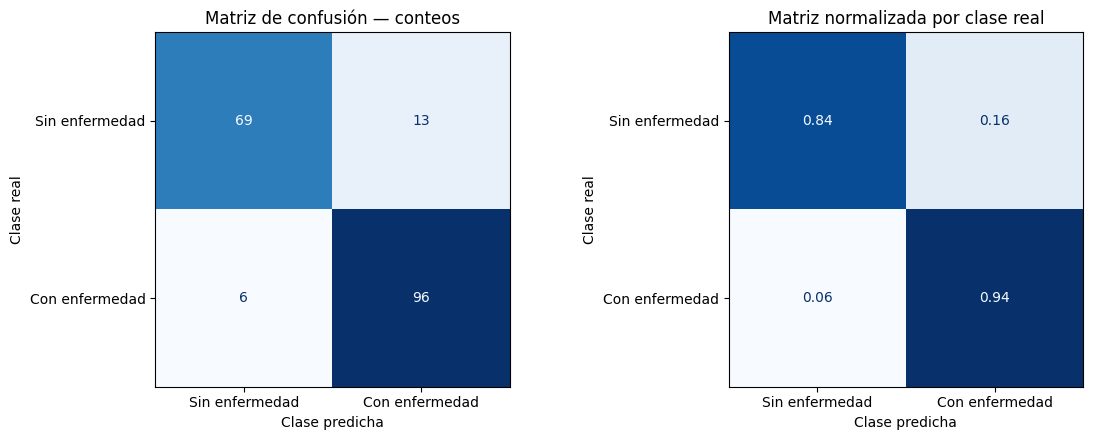

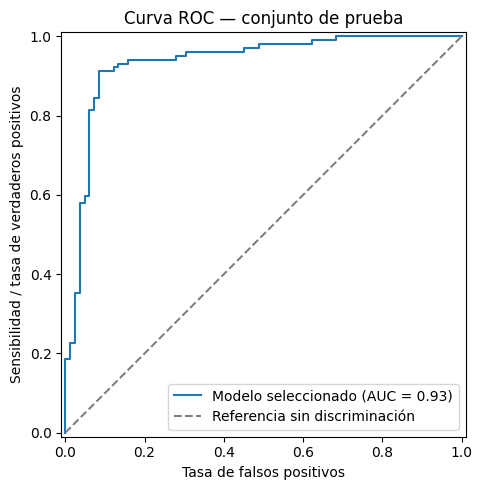

In [ ]:
# Dos representaciones complementarias de la matriz de confusión.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_real,
    y_pred_test,
    labels=[0, 1],
    display_labels=["Sin enfermedad", "Con enfermedad"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Matriz de confusión — conteos")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase real")

ConfusionMatrixDisplay.from_predictions(
    y_real,
    y_pred_test,
    labels=[0, 1],
    display_labels=["Sin enfermedad", "Con enfermedad"],
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("Matriz normalizada por clase real")
axes[1].set_xlabel("Clase predicha")
axes[1].set_ylabel("Clase real")

plt.tight_layout()
plt.show()

# Curva ROC usando las probabilidades de la clase positiva.
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_real,
    prob_test,
    name="Modelo seleccionado",
    ax=ax,
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Referencia sin discriminación",
)

ax.set_title("Curva ROC — conjunto de prueba")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Sensibilidad / tasa de verdaderos positivos")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

### **3.3. Visualización de los resultados**

Se presentan tres figuras:

1. **Matriz de confusión con conteos:** muestra el número de aciertos y errores por clase.
2. **Matriz de confusión normalizada por fila:** permite observar qué proporción de cada clase real fue clasificada correctamente.
3. **Curva ROC:** muestra la relación entre sensibilidad y tasa de falsos positivos al variar el umbral de clasificación.

La curva ROC se utiliza para describir la discriminación del modelo. No se seleccionará un nuevo umbral utilizando estos datos de prueba.

Las probabilidades predichas no se interpretarán automáticamente como riesgos clínicos calibrados, ya que la calibración no ha sido evaluada.

In [ ]:
# Construir el análisis a partir de los resultados calculados.
# No contiene cifras de desempeño escritas manualmente.
analisis_test = f"""
### **3.4. Análisis de los resultados**

**Desempeño global**

El modelo se evaluó sobre **{len(y_real)} registros de prueba**.
Clasificó correctamente **{tn + tp} registros** y cometió
**{fp + fn} errores**, obteniendo una exactitud de
**{accuracy_test:.2%}**.

La exactitud resume el desempeño global, pero debe interpretarse junto
con los errores de cada clase.

**Detección de la clase positiva**

De los **{tp + fn} registros con enfermedad cardíaca**,
el modelo identificó correctamente **{tp}** y clasificó
incorrectamente **{fn}** como negativos.

Esto corresponde a un recall o sensibilidad de **{recall_test:.2%}**.
La proporción de casos positivos no detectados fue de
**{fn / (tp + fn):.2%}**.

Estos falsos negativos constituyen una limitación relevante frente al
objetivo de identificar registros positivos.

**Precisión de las predicciones positivas**

El modelo clasificó **{tp + fp} registros como positivos**.
De ellos, **{tp}** correspondían a casos positivos reales y
**{fp}** eran falsos positivos.

La precisión de la clase positiva fue de **{precision_test:.2%}**.
El F1 de esta clase fue de **{f1_test:.4f}**, combinando precisión
y recall en una sola medida.

**Identificación de la clase negativa**

De los **{tn + fp} registros sin enfermedad cardíaca**,
se identificaron correctamente **{tn}**.

La especificidad fue de **{specificity_test:.2%}**.
La tasa de falsos positivos fue de **{fp / (tn + fp):.2%}**.

**Capacidad de discriminación**

El ROC-AUC fue de **{auc_test:.4f}**. Esta medida se calculó usando
las probabilidades de la clase positiva y resume la discriminación
entre las clases a través de distintos umbrales.

El AUC no representa el porcentaje de aciertos ni demuestra que las
probabilidades estén calibradas.

**Alcance de la evaluación**

Los resultados corresponden a una única partición de prueba del conjunto
disponible. No demuestran que el modelo alcance el mismo desempeño en
otra institución, población o procedimiento de adquisición de datos.

No se modificaron los hiperparámetros, el preprocesamiento ni la regla de
decisión como consecuencia de esta evaluación.
"""

display(Markdown(analisis_test))


### **3.4. Análisis de los resultados**

**Desempeño global**

El modelo se evaluó sobre **184 registros de prueba**.
Clasificó correctamente **165 registros** y cometió
**19 errores**, obteniendo una exactitud de
**89.67%**.

La exactitud resume el desempeño global, pero debe interpretarse junto
con los errores de cada clase.

**Detección de la clase positiva**

De los **102 registros con enfermedad cardíaca**,
el modelo identificó correctamente **96** y clasificó
incorrectamente **6** como negativos.

Esto corresponde a un recall o sensibilidad de **94.12%**.
La proporción de casos positivos no detectados fue de
**5.88%**.

Estos falsos negativos constituyen una limitación relevante frente al
objetivo de identificar registros positivos.

**Precisión de las predicciones positivas**

El modelo clasificó **109 registros como positivos**.
De ellos, **96** correspondían a casos positivos reales y
**13** eran falsos positivos.

La precisión de la clase positiva fue de **88.07%**.
El F1 de esta clase fue de **0.9100**, combinando precisión
y recall en una sola medida.

**Identificación de la clase negativa**

De los **82 registros sin enfermedad cardíaca**,
se identificaron correctamente **69**.

La especificidad fue de **84.15%**.
La tasa de falsos positivos fue de **15.85%**.

**Capacidad de discriminación**

El ROC-AUC fue de **0.9342**. Esta medida se calculó usando
las probabilidades de la clase positiva y resume la discriminación
entre las clases a través de distintos umbrales.

El AUC no representa el porcentaje de aciertos ni demuestra que las
probabilidades estén calibradas.

**Alcance de la evaluación**

Los resultados corresponden a una única partición de prueba del conjunto
disponible. No demuestran que el modelo alcance el mismo desempeño en
otra institución, población o procedimiento de adquisición de datos.

No se modificaron los hiperparámetros, el preprocesamiento ni la regla de
decisión como consecuencia de esta evaluación.


In [ ]:
# Construir el análisis a partir de los resultados calculados.
# No contiene cifras de desempeño escritas manualmente.
analisis_test = f"""
### **3.4. Análisis de los resultados**

**Desempeño global**

El modelo se evaluó sobre **{len(y_real)} registros de prueba**.
Clasificó correctamente **{tn + tp} registros** y cometió
**{fp + fn} errores**, obteniendo una exactitud de
**{accuracy_test:.2%}**.

La exactitud resume el desempeño global, pero debe interpretarse junto
con los errores de cada clase.

**Detección de la clase positiva**

De los **{tp + fn} registros con enfermedad cardíaca**,
el modelo identificó correctamente **{tp}** y clasificó
incorrectamente **{fn}** como negativos.

Esto corresponde a un recall o sensibilidad de **{recall_test:.2%}**.
La proporción de casos positivos no detectados fue de
**{fn / (tp + fn):.2%}**.

Estos falsos negativos constituyen una limitación relevante frente al
objetivo de identificar registros positivos.

**Precisión de las predicciones positivas**

El modelo clasificó **{tp + fp} registros como positivos**.
De ellos, **{tp}** correspondían a casos positivos reales y
**{fp}** eran falsos positivos.

La precisión de la clase positiva fue de **{precision_test:.2%}**.
El F1 de esta clase fue de **{f1_test:.4f}**, combinando precisión
y recall en una sola medida.

**Identificación de la clase negativa**

De los **{tn + fp} registros sin enfermedad cardíaca**,
se identificaron correctamente **{tn}**.

La especificidad fue de **{specificity_test:.2%}**.
La tasa de falsos positivos fue de **{fp / (tn + fp):.2%}**.

**Capacidad de discriminación**

El ROC-AUC fue de **{auc_test:.4f}**. Esta medida se calculó usando
las probabilidades de la clase positiva y resume la discriminación
entre las clases a través de distintos umbrales.

El AUC no representa el porcentaje de aciertos ni demuestra que las
probabilidades estén calibradas.

**Alcance de la evaluación**

Los resultados corresponden a una única partición de prueba del conjunto
disponible. No demuestran que el modelo alcance el mismo desempeño en
otra institución, población o procedimiento de adquisición de datos.

No se modificaron los hiperparámetros, el preprocesamiento ni la regla de
decisión como consecuencia de esta evaluación.
"""

display(Markdown(analisis_test))


### **3.4. Análisis de los resultados**

**Desempeño global**

El modelo se evaluó sobre **184 registros de prueba**.
Clasificó correctamente **165 registros** y cometió
**19 errores**, obteniendo una exactitud de
**89.67%**.

La exactitud resume el desempeño global, pero debe interpretarse junto
con los errores de cada clase.

**Detección de la clase positiva**

De los **102 registros con enfermedad cardíaca**,
el modelo identificó correctamente **96** y clasificó
incorrectamente **6** como negativos.

Esto corresponde a un recall o sensibilidad de **94.12%**.
La proporción de casos positivos no detectados fue de
**5.88%**.

Estos falsos negativos constituyen una limitación relevante frente al
objetivo de identificar registros positivos.

**Precisión de las predicciones positivas**

El modelo clasificó **109 registros como positivos**.
De ellos, **96** correspondían a casos positivos reales y
**13** eran falsos positivos.

La precisión de la clase positiva fue de **88.07%**.
El F1 de esta clase fue de **0.9100**, combinando precisión
y recall en una sola medida.

**Identificación de la clase negativa**

De los **82 registros sin enfermedad cardíaca**,
se identificaron correctamente **69**.

La especificidad fue de **84.15%**.
La tasa de falsos positivos fue de **15.85%**.

**Capacidad de discriminación**

El ROC-AUC fue de **0.9342**. Esta medida se calculó usando
las probabilidades de la clase positiva y resume la discriminación
entre las clases a través de distintos umbrales.

El AUC no representa el porcentaje de aciertos ni demuestra que las
probabilidades estén calibradas.

**Alcance de la evaluación**

Los resultados corresponden a una única partición de prueba del conjunto
disponible. No demuestran que el modelo alcance el mismo desempeño en
otra institución, población o procedimiento de adquisición de datos.

No se modificaron los hiperparámetros, el preprocesamiento ni la regla de
decisión como consecuencia de esta evaluación.


### **3.5. Limitaciones y conclusión de la evaluación**

La evaluación se realizó sobre la partición de prueba reservada, utilizando el Pipeline seleccionado mediante validación cruzada.

La interpretación de los resultados debe considerar:

- El tamaño limitado del conjunto de prueba.
- La procedencia y representatividad de los registros.
- El desequilibrio en la representación de hombres y mujeres identificado en la fase exploratoria.
- La imputación de colesterol y presión arterial, que no recupera las mediciones originales.
- La posibilidad de que `Cholesterol_missing` represente diferencias de registro o procedencia.
- La exploración del conjunto completo realizada en fases anteriores.
- La ausencia de validación externa y de evaluación de calibración.

Los resultados de validación cruzada y de prueba cumplen funciones distintas: los primeros permitieron seleccionar la configuración y los segundos describen su desempeño posterior en la partición reservada. Una diferencia entre ambos no demuestra por sí sola sobreajuste, pues también puede deberse a variabilidad de muestreo.

Esta evaluación no se utilizará para iniciar otra búsqueda de hiperparámetros sobre la misma prueba. Si se realizan cambios guiados por estos resultados, deberá reconocerse que dicha partición ha pasado a influir en el desarrollo y será necesaria una evaluación independiente adicional.

El modelo constituye un prototipo académico. Su eventual uso sobre pacientes requeriría validación externa, revisión profesional y análisis de su comportamiento en distintos grupos.

---

**Fin de la sección 3: evaluación del modelo sobre el conjunto de prueba.**

## **4. Aplicación del modelo**
---

Una vez que haya entrenado y evaluado su modelo, es importante considerar cómo puede ser utilizado en un entorno práctico.

Intente analizar la capacidad del modelo para generalizar nuevos datos que no formaron parte del conjunto de entrenamiento o evaluación.


### **4.1. Propósito de la aplicación**

Se utilizará el Pipeline entrenado para generar predicciones sobre registros nuevos con la misma estructura de variables utilizada durante el desarrollo.

El procedimiento comprende:

1. Recibir las características originales del nuevo registro.
2. Validar su estructura y sus valores.
3. Aplicar las reglas de limpieza definidas en la fase de preparación.
4. Utilizar el Pipeline para transformar las características y generar predicciones.
5. Presentar la clase predicha y la probabilidad estimada para la clase positiva.

No se volverá a entrenar el modelo ni se recalcularán los parámetros de imputación, codificación o escalado con los nuevos datos.


### **4.2. Datos para la demostración**

Se construirán registros sintéticos con fines ilustrativos. Estos registros:

- No representan pacientes reales.
- No se extraen de las particiones de entrenamiento o prueba.
- No contienen la variable objetivo `HeartDisease`.
- No tienen diagnósticos conocidos que permitan determinar si las predicciones son correctas.

Se comprobará que sus características originales no coincidan exactamente con las del conjunto utilizado en el proyecto.

La demostración permite verificar la aplicación técnica del modelo. No constituye una validación externa ni evidencia de utilidad clínica.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.utils.validation import check_is_fitted

# Verificar que se dispone del modelo entrenado y de los datos originales.
if "modelo_final" not in globals() or "df_original" not in globals():
    raise RuntimeError(
        "Ejecuta primero la sección 2 para crear modelo_final y df_original."
    )

check_is_fitted(modelo_final)

# Las columnas deben coincidir con las características originales.
COLUMNAS_ORIGINALES = [
    "Age",
    "Sex",
    "ChestPainType",
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "RestingECG",
    "MaxHR",
    "ExerciseAngina",
    "Oldpeak",
    "ST_Slope",
]

# Ejemplos artificiales para demostrar el funcionamiento.
# No se asignan etiquetas reales ni se anticipan las predicciones.
nuevos_datos = pd.DataFrame([
    {
        "Age": 43,
        "Sex": "F",
        "ChestPainType": "ATA",
        "RestingBP": 123,
        "Cholesterol": 207,
        "FastingBS": 0,
        "RestingECG": "Normal",
        "MaxHR": 169,
        "ExerciseAngina": "N",
        "Oldpeak": 0.3,
        "ST_Slope": "Up",
    },
    {
        "Age": 62,
        "Sex": "M",
        "ChestPainType": "ASY",
        "RestingBP": 147,
        "Cholesterol": 281,
        "FastingBS": 1,
        "RestingECG": "LVH",
        "MaxHR": 112,
        "ExerciseAngina": "Y",
        "Oldpeak": 2.4,
        "ST_Slope": "Flat",
    },
    {
        "Age": 56,
        "Sex": "F",
        "ChestPainType": "NAP",
        "RestingBP": 137,
        "Cholesterol": np.nan,
        "FastingBS": 0,
        "RestingECG": "Normal",
        "MaxHR": 146,
        "ExerciseAngina": "N",
        "Oldpeak": 0.8,
        "ST_Slope": "Flat",
    },
], columns=COLUMNAS_ORIGINALES)

nuevos_datos.index = [
    "Ejemplo sintético A",
    "Ejemplo sintético B",
    "Ejemplo sintético C",
]
nuevos_datos.index.name = "Registro"

# Comprobar coincidencias exactas con las características originales.
# Se iguala la representación de ceros sospechosos y valores ausentes
# para que esa diferencia de codificación no oculte una coincidencia.
referencia = df_original[COLUMNAS_ORIGINALES].copy()
candidatos = nuevos_datos.copy()

for datos in [referencia, candidatos]:
    datos[["Cholesterol", "RestingBP"]] = (
        datos[["Cholesterol", "RestingBP"]].replace(0, np.nan)
    )

coincidencias = candidatos.merge(
    referencia.drop_duplicates(),
    on=COLUMNAS_ORIGINALES,
    how="inner",
)

assert coincidencias.empty, (
    "Algún ejemplo coincide con un registro del conjunto original."
)

print("Registros sintéticos sin coincidencias exactas con el conjunto original:")
display(nuevos_datos)

Registros sintéticos sin coincidencias exactas con el conjunto original:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
Registro,,,,,,,,,,,
Ejemplo sintético A,43,F,ATA,123,207.0,0,Normal,169,N,0.3,Up
Ejemplo sintético B,62,M,ASY,147,281.0,1,LVH,112,Y,2.4,Flat
Ejemplo sintético C,56,F,NAP,137,NaN,0,Normal,146,N,0.8,Flat


In [ ]:
def preparar_nuevas_entradas(datos):
    """
    Validar registros nuevos y aplicar únicamente reglas deterministas.
    No ajusta transformadores ni utiliza etiquetas.
    """
    if not isinstance(datos, pd.DataFrame):
        raise TypeError("Los registros deben proporcionarse en un DataFrame.")

    if datos.empty:
        raise ValueError("El DataFrame no contiene registros.")

    if not datos.columns.is_unique:
        raise ValueError("Existen nombres de columnas duplicados.")

    faltantes = set(COLUMNAS_ORIGINALES) - set(datos.columns)
    adicionales = set(datos.columns) - set(COLUMNAS_ORIGINALES)

    if faltantes or adicionales:
        raise ValueError(
            f"Columnas faltantes: {sorted(faltantes)}. "
            f"Columnas adicionales: {sorted(adicionales)}."
        )

    limpio = datos[COLUMNAS_ORIGINALES].copy(deep=True)

    categorias_permitidas = {
        "Sex": {"M", "F"},
        "ChestPainType": {"TA", "ATA", "NAP", "ASY"},
        "FastingBS": {0, 1},
        "RestingECG": {"Normal", "ST", "LVH"},
        "ExerciseAngina": {"Y", "N"},
        "ST_Slope": {"Up", "Flat", "Down"},
    }

    # Normalizar espacios y detectar categorías no documentadas.
    for columna, permitidas in categorias_permitidas.items():
        if columna != "FastingBS":
            limpio[columna] = limpio[columna].map(
                lambda valor: valor.strip()
                if isinstance(valor, str) else valor
            )
            limpio[columna] = limpio[columna].replace("", np.nan)

        invalidos = (
            limpio[columna].notna()
            & ~limpio[columna].isin(permitidas)
        )

        if invalidos.any():
            raise ValueError(
                f"Categorías no válidas en {columna}: "
                f"{limpio.loc[invalidos, columna].tolist()}"
            )

    # Verificar las variables numéricas.
    columnas_numericas = [
        "Age", "RestingBP", "Cholesterol",
        "MaxHR", "Oldpeak", "FastingBS",
    ]

    for columna in columnas_numericas:
        limpio[columna] = pd.to_numeric(
            limpio[columna], errors="raise"
        )

        valores = limpio[columna].dropna().to_numpy(dtype=float)

        if not np.isfinite(valores).all():
            raise ValueError(f"Valores infinitos en {columna}.")

    for columna in ["Age", "MaxHR"]:
        if limpio[columna].le(0).any():
            raise ValueError(f"{columna} debe ser mayor que cero.")

    for columna in ["RestingBP", "Cholesterol"]:
        if limpio[columna].lt(0).any():
            raise ValueError(f"{columna} no puede ser negativo.")

    # Crear el indicador antes de reemplazar los ceros.
    limpio["Cholesterol_missing"] = (
        limpio["Cholesterol"].isna()
        | limpio["Cholesterol"].eq(0)
    ).astype(int)

    limpio[["Cholesterol", "RestingBP"]] = (
        limpio[["Cholesterol", "RestingBP"]].replace(0, np.nan)
    )

    return limpio


def aplicar_modelo(modelo, datos):
    """
    Aplicar un Pipeline ya entrenado a registros nuevos.
    Retorna resultados y entradas preparadas para auditoría.
    """
    check_is_fitted(modelo)

    preparados = preparar_nuevas_entradas(datos)

    # Recuperar exactamente las columnas y el orden usados al entrenar.
    columnas_modelo = list(modelo.feature_names_in_)
    preparados = preparados.loc[:, columnas_modelo]

    predicciones = modelo.predict(preparados)

    clases = np.asarray(modelo.classes_)
    posicion_positiva = np.flatnonzero(clases == 1)

    if len(posicion_positiva) != 1:
        raise ValueError("No se encontró la clase positiva 1.")

    probabilidades = modelo.predict_proba(preparados)[
        :, posicion_positiva[0]
    ]

    resultados = pd.DataFrame({
        "Clase predicha": predicciones,
        "Probabilidad clase 1": probabilidades,
        "Colesterol ausente o cero": preparados[
            "Cholesterol_missing"
        ].astype(bool),
    }, index=datos.index)

    resultados["Interpretación de la clase"] = resultados[
        "Clase predicha"
    ].map({
        0: "Predicción de ausencia de enfermedad",
        1: "Predicción de presencia de enfermedad",
    })

    return resultados, preparados


# Ejecutar la aplicación sin volver a entrenar el modelo.
resultados_nuevos, entradas_preparadas = aplicar_modelo(
    modelo_final, nuevos_datos
)

display(resultados_nuevos.round(4))

,Clase predicha,Probabilidad clase 1,Colesterol ausente o cero,Interpretación de la clase
Registro,,,,
Ejemplo sintético A,0,0.0356,False,Predicción de ausencia de enfermedad
Ejemplo sintético B,1,0.9554,False,Predicción de presencia de enfermedad
Ejemplo sintético C,0,0.4690,True,Predicción de ausencia de enfermedad


In [ ]:
# Este análisis identifica valores fuera de los rangos observados.
# Estar dentro del rango NO demuestra que un ejemplo sea representativo.
columnas_numericas = [
    "Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"
]

rangos_entrenamiento = X_train[columnas_numericas].agg(
    ["min", "max"]
).T

rangos_entrenamiento.columns = [
    "Mínimo entrenamiento",
    "Máximo entrenamiento",
]

print("Rangos observados en entrenamiento:")
display(rangos_entrenamiento)

revision_nuevos = []

for registro, fila in entradas_preparadas.iterrows():
    for variable in columnas_numericas:
        valor = fila[variable]
        minimo = rangos_entrenamiento.loc[
            variable, "Mínimo entrenamiento"
        ]
        maximo = rangos_entrenamiento.loc[
            variable, "Máximo entrenamiento"
        ]

        if pd.isna(valor):
            estado = "Ausente: se imputa dentro del Pipeline"
        elif valor < minimo or valor > maximo:
            estado = "Fuera del rango observado"
        else:
            estado = "Dentro del rango observado"

        revision_nuevos.append({
            "Registro": registro,
            "Variable": variable,
            "Valor recibido": valor,
            "Revisión": estado,
        })

revision_nuevos = pd.DataFrame(revision_nuevos)
display(revision_nuevos)

Rangos observados en entrenamiento:


,Mínimo entrenamiento,Máximo entrenamiento
Age,29.0,77.0
RestingBP,92.0,200.0
Cholesterol,85.0,603.0
MaxHR,60.0,202.0
Oldpeak,-2.6,5.6


,Registro,Variable,Valor recibido,Revisión
0,Ejemplo sintético A,Age,43.0,Dentro del rango observado
1,Ejemplo sintético A,RestingBP,123.0,Dentro del rango observado
2,Ejemplo sintético A,Cholesterol,207.0,Dentro del rango observado
3,Ejemplo sintético A,MaxHR,169.0,Dentro del rango observado
4,Ejemplo sintético A,Oldpeak,0.3,Dentro del rango observado
5,Ejemplo sintético B,Age,62.0,Dentro del rango observado
6,Ejemplo sintético B,RestingBP,147.0,Dentro del rango observado
7,Ejemplo sintético B,Cholesterol,281.0,Dentro del rango observado
8,Ejemplo sintético B,MaxHR,112.0,Dentro del rango observado
9,Ejemplo sintético B,Oldpeak,2.4,Dentro del rango observado


### **4.4. Interpretación de la aplicación**

La tabla y la gráfica presentan las predicciones del modelo sobre registros sintéticos nuevos. Cada probabilidad corresponde a la salida del clasificador para la clase positiva, según los patrones aprendidos durante el entrenamiento.

No se dispone de diagnósticos reales para estos ejemplos. Por tanto, no es posible calcular su exactitud, sensibilidad o F1, ni afirmar que una predicción es correcta.

El ejemplo con colesterol ausente permite comprobar que el proceso reconoce la falta de información, construye el indicador correspondiente y utiliza la mediana aprendida en entrenamiento. No se calcula una nueva mediana con los registros de la demostración.

Las probabilidades obtenidas no se interpretan automáticamente como riesgo clínico individual, ya que no se ha realizado una evaluación de calibración.

### **4.5. Capacidad de generalización**

La evaluación sobre la partición de prueba realizada en la sección 3 aporta evidencia de desempeño sobre observaciones reservadas del conjunto disponible.

Sin embargo, una partición aleatoria de la misma fuente no demuestra que el modelo mantenga su comportamiento en otras instituciones, poblaciones o periodos.

La revisión de rangos permite detectar algunas diferencias evidentes entre las nuevas entradas y el entrenamiento. Estar dentro de los rangos observados no garantiza que una combinación de características sea habitual o esté suficientemente representada.

Las principales limitaciones para la generalización son:

- **Tamaño del conjunto:** los datos disponibles representan una muestra limitada.
- **Representación desigual de grupos:** la distribución por sexo identificada en la fase exploratoria puede afectar el desempeño en subpoblaciones.
- **Cambios de distribución:** otras poblaciones pueden presentar diferentes edades, condiciones clínicas o frecuencias de enfermedad.
- **Diferencias de medición y registro:** las unidades, categorías o procedimientos de captura pueden variar entre instituciones.
- **Información ausente:** el indicador de colesterol podría capturar características de la fuente de datos.
- **Imputación:** reemplazar una medición ausente no recupera su valor real.
- **Ausencia de validación externa:** no se ha evaluado el modelo con un conjunto independiente procedente de otra institución o periodo.

### **4.6. Uso práctico propuesto**

El producto puede utilizarse como una demostración académica de un flujo reproducible:

**Ingreso de características → validación → limpieza determinista → Pipeline entrenado → predicción y registro del resultado.**

Antes de considerar una aplicación real sería necesario:

1. Evaluar datos externos con etiquetas confiables y sin reutilizarlos para ajustar el modelo.
2. Examinar el desempeño por grupos relevantes, indicando el tamaño de cada submuestra.
3. Evaluar la calibración de probabilidades si se pretende interpretarlas como riesgo.
4. Definir los costos de los errores y cualquier umbral operativo con datos de desarrollo, no con la prueba final.
5. Monitorizar categorías nuevas, valores ausentes y cambios en la distribución de las características.
6. Establecer supervisión profesional y mecanismos de protección de los datos.

### **4.7. Conclusión**

Se implementó una función para aplicar el modelo entrenado a registros nuevos, manteniendo el esquema de entrada y las reglas de preparación del proyecto.

La demostración permite comprobar el funcionamiento técnico del proceso sin volver a ajustar el modelo. No permite medir desempeño sobre los ejemplos sintéticos ni demostrar generalización clínica.

La evidencia predictiva disponible corresponde a la evaluación de prueba de la sección anterior. Una afirmación más amplia sobre generalización requerirá datos externos y una evaluación independiente.

---

## **Fin del tema: modelamiento, validación y aplicación**

Con esta sección finaliza la cuarta fase del proyecto aplicado. Se documentaron la selección de modelos, la búsqueda de hiperparámetros, la evaluación sobre prueba y una demostración de aplicación a nuevas entradas.

**El resultado es un prototipo académico y no sustituye la evaluación médica.**

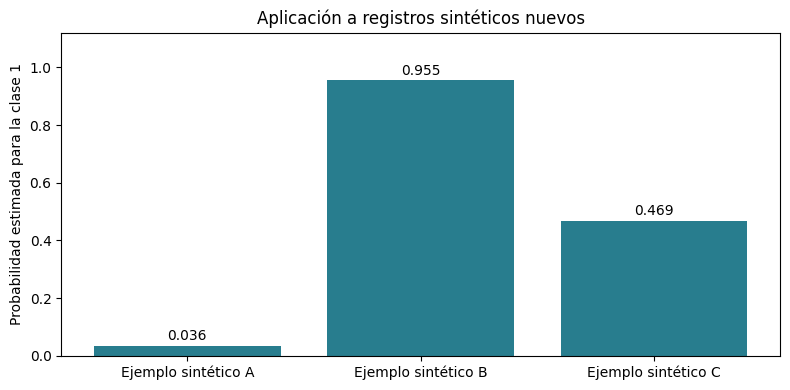

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

posiciones = np.arange(len(resultados_nuevos))

barras = ax.bar(
    posiciones,
    resultados_nuevos["Probabilidad clase 1"],
    color="#287D8E",
)

ax.set_xticks(posiciones, resultados_nuevos.index)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Probabilidad estimada para la clase 1")
ax.set_title("Aplicación a registros sintéticos nuevos")

for barra, probabilidad in zip(
    barras, resultados_nuevos["Probabilidad clase 1"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.02,
        f"{probabilidad:.3f}",
        ha="center",
    )

plt.tight_layout()
plt.show()

### **4.3. Validación y preparación de nuevas entradas**

Se aplicarán las mismas reglas deterministas utilizadas durante el desarrollo:

- Comprobar la presencia de todas las variables requeridas.
- Validar tipos numéricos, categorías y ausencia de valores infinitos.
- Rechazar valores negativos en colesterol y presión arterial.
- Representar los ceros de colesterol y presión arterial mediante valores ausentes.
- Construir `Cholesterol_missing` cuando el colesterol sea cero o esté ausente.

La función no estimará medianas ni escalas. La imputación y las transformaciones estadísticas se realizarán con el Pipeline previamente ajustado.

Como control de calidad, la aplicación rechazará categorías no documentadas, aunque el codificador del Pipeline pueda procesar categorías desconocidas. Esta decisión evita aceptar silenciosamente errores de escritura o cambios en el formato de entrada.

Estas validaciones son controles técnicos básicos; no certifican la validez clínica de un registro.

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*